## Лабораторная работа №3. Кластеризация

**Датасет:** Student Depression Detection (Выявление депрессии у студентов)

**Цель работы:** изучение алгоритмов кластеризации, приобретение навыков оценки качества разбиения данных на кластеры и интерпретации результатов.

---

### Постановка задачи

1. Загрузить датасет. Провести дескриптивный анализ данных: определить размерность, типы признаков, наличие пропусков. Оценить распределение переменных (близость к нормальному) с использованием визуализации (гистограммы). Оценить информационную значимость признаков. Проверить условие применения кластеризации: отсутствие классов, осмысленность кластеризации, отсутствие выбросов.

2. Выполнить стандартизацию / нормализацию числовых признаков. Обосновать выбор метода масштабирования. Построить матрицу диаграмм рассеивания для визуальной оценки структуры данных, предположительного количества кластеров и типа кластерной структуры. Аргументировать выбор методов кластеризации на основе формы, размера и плотности кластеров.

3. Реализовать кластеризацию двумя различными методами на выбор: K-means (K-средних); иерархическая кластеризация; DBSCAN; EM-алгоритм (Gaussian Mixture). Для методов, требующих задания числа кластеров (K-means, иерархическая), подобрать оптимальное значение k с использованием: метода локтя и / или анализа силуэта.

4. Рассчитать метрики качества для обоих методов: внутренние и внешние. Оценить расстояние между кластерами, внутрикластерные расстояния, компактность кластеров, центры кластеров. Опционально, если известно разделение на классы, посчитать: индекс Rand, индекс Жаккара и др. внешние метрики. Привести содержательную интерпретацию полученных значений.

5. Исследовать влияние параметров одного из методов (например, ε и min_samples для DBSCAN или количества кластеров k для K-means) на качество кластеризации.

6. Визуализировать полученные кластеры в пространстве признаков (использовать PCA для снижения размерности при необходимости). Проанализировать центры кластеров и дать содержательную интерпретацию выделенных групп. Сравнить результаты, полученные двумя разными методами.


In [29]:
import pandas as pd
from sklearn.decomposition import PCA
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
import seaborn as sns
import math
from scipy.stats import skew, kurtosis, normaltest
import warnings
import numpy as np
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
from scipy.stats import beta
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    silhouette_score, 
    calinski_harabasz_score, 
    davies_bouldin_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
    v_measure_score,
    homogeneity_score,
    completeness_score
)

from kneed import KneeLocator

Подключаем необходимые для работы библиотеки.

In [30]:
df = pd.read_excel('data.xlsx', engine='openpyxl')
df.columns = df.columns.str.strip()

df = df.head(4000).reset_index(drop=True)

print("Размер датасета (строк, столбцов):", df.shape)
df.head()

Размер датасета (строк, столбцов): (4000, 12)


,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Yes


### Описание датасета

Датасет **Spambase**  содержит **11 переменных** одна из которых целевая переменная - **`Depression`**. 

| Переменная | Описание | Тип |
| --- | --- | --- |
| `Gender` | пол студента | категориальная номинальная независимая |
| `Age` | 	возраст студента | числовая дискретная независимая |
| `Family_background` | положение семьи | категориальная номинальная независимая |
| `Relationship_status` | наличие романтических отношений | категориальная номинальная независимая |
| `Marital_status` | семейное положение | категориальная номинальная независимая |
| `Current_semester` | текущий семестр обучения | категориальная номинальная независимая |
| `CGPA` | средний академический балл | числовая непрерывная независимая |
| `friend_circle` | наличие и размер круга общения | категориальная номинальная независимая |
| `Cost_without_study` | расходы, не связанные с учёбой | числовая непрерывная независимая |
| `Health_condition` | состояние здоровья | категориальная номинальная независимая |
| **`Depression`** | **признак депрессии: 1 — есть, 0 — нет** | **числовая дискретная зависимая (целевая)** |

In [31]:
df.info()
print()
print("Пропущенных значений всего:", df.isna().sum().sum())
print("Полных дубликатов строк:", df.duplicated().sum())
df.describe().T.round(3)

<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4000 non-null   str    
 1   Age                  4000 non-null   int64  
 2   Family_background    4000 non-null   str    
 3   Relationship_status  4000 non-null   str    
 4   Marital_status       4000 non-null   str    
 5   Living_style         4000 non-null   str    
 6   Current_semester     4000 non-null   int64  
 7   CGPA                 4000 non-null   float64
 8   friend_circle        4000 non-null   str    
 9   Health_condition     4000 non-null   str    
 10  Cost_without_study   4000 non-null   int64  
 11  Depression           4000 non-null   str    
dtypes: float64(1), int64(3), str(8)
memory usage: 375.1 KB

Пропущенных значений всего: 0
Полных дубликатов строк: 3


,count,mean,std,min,25%,50%,75%,max
Age,4000.0,22.608,2.033,17.00,21.00,23.00,24.0,28.0
Current_semester,4000.0,5.321,2.583,0.00,3.00,5.00,7.0,13.0
CGPA,4000.0,3.411,0.385,2.25,3.16,3.49,3.7,4.0
Cost_without_study,4000.0,10787.294,6458.860,0.00,6000.00,9000.00,14867.0,32000.0


In [32]:
df.describe(include='str').T.round(3)

,count,unique,top,freq
Gender,4000,2,Female,2222
Family_background,4000,3,Middle class,2386
Relationship_status,4000,3,Single,2525
Marital_status,4000,3,Unmarried,3299
Living_style,4000,2,Bachelor,2148
friend_circle,4000,2,Yes,2900
Health_condition,4000,4,Normal,1615
Depression,4000,2,No,2940


             Параметр  Асимметрия  Эксцесс
0                 Age      0.0740  -0.1809
1    Current_semester      0.3687  -0.4919
2                CGPA     -0.6139  -0.2707
3  Cost_without_study      0.9293   0.2945

Проверка нормальности (тест Д’Агостино-Пирсона):
Age: статистика=9.9933, p-значение=0.0068 → отличается от нормального

Current_semester: статистика=157.7700, p-значение=0.0000 → отличается от нормального

CGPA: статистика=231.4475, p-значение=0.0000 → отличается от нормального

Cost_without_study: статистика=436.7734, p-значение=0.0000 → отличается от нормального

Число бинов по формуле Стерджеса: 12



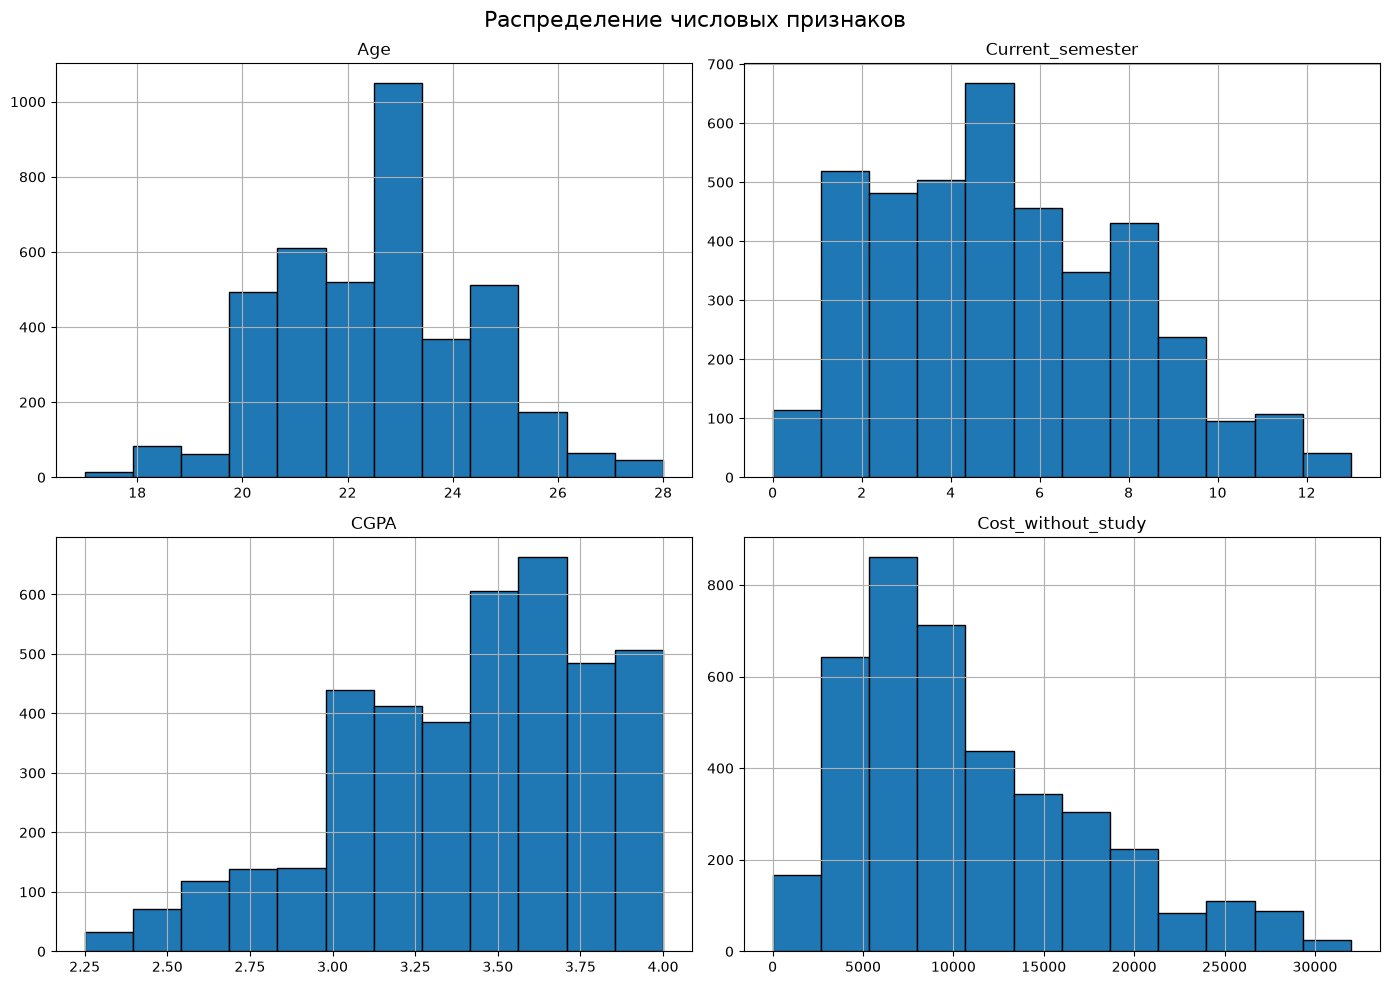

CGPA: найдено 20 выбросов (границы: 2.35 – 4.51)
Cost_without_study: найдено 64 выбросов (границы: -7300.50 – 28167.50)


{'Age': 0, 'Current_semester': 0, 'CGPA': 20, 'Cost_without_study': 64}

In [33]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

features_only = [c for c in numeric_cols if c != TARGET] \
                if 'TARGET' in globals() else numeric_cols


data = {'Параметр': [], 'Асимметрия': [], 'Эксцесс': []}

with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    for col in features_only:
        vals = df[col].dropna()
        data['Параметр'].append(col)
        data['Асимметрия'].append(skew(vals))
        data['Эксцесс'].append(kurtosis(vals))

summary_df = pd.DataFrame(data)
print(summary_df.round(4))


print("\nПроверка нормальности (тест Д’Агостино-Пирсона):")

with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    for col in features_only:
        vals = df[col].dropna()
        stat, p = normaltest(vals)
        verdict = ("близко к нормальному"
                   if p > 0.05 else "отличается от нормального")
        print(f"{col}: статистика={stat:.4f}, "
              f"p-значение={p:.4f} → {verdict}\n")


count_of_bins = int(1 + 3.322 * math.log10(df.shape[0]))
print(f"Число бинов по формуле Стерджеса: {count_of_bins}\n")

df[features_only].hist(
    bins=count_of_bins,
    figsize=(14, 10),
    edgecolor="black"
)
plt.suptitle("Распределение числовых признаков", fontsize=16)
plt.tight_layout()
plt.show()

def find_outliers_iqr(df, cols=None):
    if cols is None:
        cols = df.select_dtypes(include=[np.number]).columns
    
    outliers_dict = {}
    for col in cols:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        
        # Находим индексы выбросов
        outlier_indices = df[(df[col] < lower_bound) | (df[col] > upper_bound)].index
        outliers_dict[col] = len(outlier_indices)
        
        if len(outlier_indices) > 0:
            print(f"{col}: найдено {len(outlier_indices)} выбросов (границы: {lower_bound:.2f} – {upper_bound:.2f})")
    
    return outliers_dict



find_outliers_iqr(df, numeric_cols)

In [34]:
TARGET = 'Depression'

X = df.drop(columns=[TARGET]).copy()
y = df[TARGET].copy()

cat_cols = X.select_dtypes(include=['object', 'str', 'category']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object', 'str', 'category']).columns.tolist()

X_encoded = pd.get_dummies(X, columns=cat_cols, drop_first=True, dtype=int)

df_encoded = X_encoded.copy()
corr_matrix = df_encoded.corr(method='spearman').abs()

upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

threshold = 0.7

strong_pairs = (
    upper.stack()
    .reset_index()
    .rename(columns={'level_0': 'feature_1', 'level_1': 'feature_2', 0: 'abs_corr'})
    .query('abs_corr >= @threshold')
    .sort_values('abs_corr', ascending=False)
    .reset_index(drop=True)
)

print(f"\nПар признаков с |corr| >= {threshold}: {len(strong_pairs)}\n")
print(strong_pairs.to_string(index=False))


Пар признаков с |corr| >= 0.7: 1

                            feature_1                  feature_2  abs_corr
Relationship_status_In a Relationship Relationship_status_Single  0.909942


### Корреляционный и дескриптивный анализ

**Дескриптивный анализ** показал, что признаки имеют разный масштаб (например, `Cost_without_study` достигает тысяч, `GGPA` — максимально достигает четырех). 

Тест Д’Агостино-Пирсона показал, что **распределения не соответствуют нормальному**. 

В признаке Cost_without_study было выявлено **64 выброса (1.6% выборки)**, что отражает студентов с аномально высокими расходами, не связанными с учёбой. Эти значения образуют длинный правый хвост, что делает стандартное логарифмирование (log1p) обоснованным и необходимым шагом. Логарифмирование сжимает экстремальные значения, не удаляя их из выборки и сохраняя информацию о студентах с высоким уровнем расходов, что стабилизирует расстояния для алгоритмов кластеризации и делает распределение признака ближе к нормальному.

В признаке CGPA было выявлено **20 выбросов (0.5% выборки)**. Они не являются ошибками и отражают студентов с низкой успеваемостью. Эти выбросы были оставлены в выборке, так как их количество статистически незначительно и они не оказывают существенного влияния на обучение модели

Все категориальные признаки были закодированы с помощью **One-Hot-Encoding**.

**Корреляционный анализ** показал, что в датасете имеется 1 пара признаков с сильной корреляцией - Relationship_status_In a Relationship и Relationship_status_Single.  

In [35]:
def significance_by_variability_correlation(
    df,
    exclude_cols=None,
    redundancy_threshold=0.9,
    pc1_weight=0.5,
):
    X = df.copy()
    if exclude_cols:
        X = X.drop(columns=[c for c in exclude_cols if c in X.columns])

    X = X.select_dtypes(include=[np.number])
    features = X.columns.tolist()

    if 'Cost_without_study' in X.columns:
        X['Cost_without_study'] = np.log1p(X['Cost_without_study'])

    raw_stats = pd.DataFrame({
        'raw_mean': X.mean(),
        'raw_std': X.std(),
        'raw_cv': X.std() / (X.mean().abs() + 1e-12),
        'raw_max': X.max(),
        'zero_share': (X == 0).mean(),
        'nunique': X.nunique(),
    })

    Xt = X.copy()

    Xs = pd.DataFrame(
        StandardScaler().fit_transform(Xt),
        columns=features, index=Xt.index,
    )

    var_std = Xs.std()
    var_iqr = Xs.quantile(0.75) - Xs.quantile(0.25)

    def norm01(s):
        rng = s.max() - s.min()
        return (s - s.min()) / rng if rng > 0 else pd.Series(0.0, index=s.index)

    var_score = (norm01(var_std) + norm01(var_iqr)) / 2

    corr_abs = Xs.corr().abs()
    corr_arr = corr_abs.to_numpy(copy=True)   
    np.fill_diagonal(corr_arr, 0.0)
    corr_abs = pd.DataFrame(corr_arr, index=corr_abs.index, columns=corr_abs.columns)

    max_corr_other = corr_abs.max(axis=1)
    mean_corr_other = corr_abs.mean(axis=1)

    pc1 = PCA(n_components=1, random_state=42).fit_transform(Xs)[:, 0]
    pc1_corr = Xs.apply(lambda col: np.corrcoef(col, pc1)[0, 1]).abs()

    order_by_var = var_score.sort_values(ascending=False).index.tolist()
    redundancy_penalty = pd.Series(0.0, index=features)
    accepted = []
    for c in order_by_var:
        if accepted:
            m = corr_abs.loc[c, accepted].max()
        else:
            m = 0.0
        if m >= redundancy_threshold:
            redundancy_penalty[c] = m
        else:
            accepted.append(c)

    corr_score = (
        norm01(pc1_corr) * pc1_weight
        + norm01(mean_corr_other) * (1 - pc1_weight)
    ) * (1 - redundancy_penalty)

    final_score = var_score * (1 - redundancy_penalty) + corr_score
    final_score = final_score / 2

    result = pd.concat([
        raw_stats,
        pd.DataFrame({
            'var_std_scaled': var_std,
            'var_iqr_scaled': var_iqr,
            'var_score': var_score,
            'max_corr_other': max_corr_other,
            'mean_corr_other': mean_corr_other,
            'pc1_corr': pc1_corr,
            'redundancy_penalty': redundancy_penalty,
            'corr_score': corr_score,
            'final_score': final_score,
        })
    ], axis=1).sort_values('final_score', ascending=False)

    result['rank'] = range(1, len(result) + 1)
    return result


def select_by_criteria(result, top_k=None, min_score=None, drop_redundant=True):
    r = result
    if drop_redundant:
        r = r[r['redundancy_penalty'] == 0]
    if top_k is not None:
        return r.head(top_k).index.tolist()
    if min_score is not None:
        return r[r['final_score'] >= min_score].index.tolist()
   


res = significance_by_variability_correlation(
    X_encoded,                     
    exclude_cols=None,              
    redundancy_threshold=0.9,
    pc1_weight=0.5,
)

print("Значимость признаков\n")
display(res[['rank', 'var_score', 'max_corr_other', 'pc1_corr',
             'redundancy_penalty', 'corr_score', 'final_score']])


selected = select_by_criteria(res, top_k=15, drop_redundant=True)



X_selected = X_encoded[selected].copy()

print("\nОтобранные признаки:", selected)
print("Размер датасета для кластеризации:", X_selected.shape)
X_selected.head()

Значимость признаков



,rank,var_score,max_corr_other,pc1_corr,redundancy_penalty,corr_score,final_score
Relationship_status_Single,1,0.705703,0.909942,0.833569,0.000000,0.999523,0.852613
Gender_Male,2,0.692457,0.429034,0.608869,0.000000,0.737234,0.714846
Age,3,0.574431,0.357211,0.381667,0.000000,0.472740,0.523586
Living_style_Family,4,0.440932,0.429034,0.473027,0.000000,0.588727,0.514829
Family_background_Middle class,5,0.698148,0.500708,0.154645,0.000000,0.330135,0.514142
Family_background_Rich class,6,0.500000,0.500708,0.271247,0.000000,0.432321,0.466160
Current_semester,7,0.590536,0.357211,0.263175,0.000000,0.284098,0.437317
Cost_without_study,8,0.522959,0.315197,0.179529,0.000000,0.284827,0.403893
friend_circle_Yes,9,0.742395,0.157688,0.040357,0.000000,0.063787,0.403091
Marital_status_Unmarried,10,0.000000,0.368212,0.605150,0.000000,0.766805,0.383402



Отобранные признаки: ['Relationship_status_Single', 'Gender_Male', 'Age', 'Living_style_Family', 'Family_background_Middle class', 'Family_background_Rich class', 'Current_semester', 'Cost_without_study', 'friend_circle_Yes', 'Marital_status_Unmarried', 'Health_condition_Normal', 'Health_condition_Good', 'CGPA', 'Health_condition_Critical', 'Marital_status_Separated']
Размер датасета для кластеризации: (4000, 15)


,Relationship_status_Single,Gender_Male,Age,Living_style_Family,Family_background_Middle class,Family_background_Rich class,Current_semester,Cost_without_study,friend_circle_Yes,Marital_status_Unmarried,Health_condition_Normal,Health_condition_Good,CGPA,Health_condition_Critical,Marital_status_Separated
0,1,0,22,0,1,0,8,10113,1,1,0,0,3.43,1,0
1,1,1,19,0,1,0,2,13815,1,1,0,0,3.70,0,0
2,1,1,23,1,1,0,8,15450,0,1,0,0,3.28,0,0
3,0,1,20,1,1,0,2,17413,0,1,0,1,3.77,0,0
4,1,0,21,1,1,0,1,16693,0,1,0,0,4.00,0,0


### Оценка значимости признаков

Оценка значимости проводилась по трём критериям: вариативность, коррелированность и разреженность (доля нулей, почти константные признаки). 

Признаки с высокой вариативностью и заметной связью с общей структурой данных получали высокий балл, а почти константные (Marital_status_Unmarried, Marital_status_Separated, Health_condition_Critical) — низкий.

 Из сильно коррелирующих пар оставлялся один представитель: Relationship_status_In a Relationship (corr = 0.91 с Relationship_status_Single) был удалён как дубликат. 
 
 В итоге для дальнейшей кластеризации осталось 15 признаков.

In [36]:


def hopkins_statistic(X, n_samples=None, random_state=42):
    X = np.asarray(X, dtype=float)
    n, d = X.shape

    if n_samples is None:
        n_samples = max(10, min(n // 10, n // 2))
    m = n_samples

    rng = np.random.default_rng(random_state)

    nn_real = NearestNeighbors(n_neighbors=2).fit(X)
    dist_real, _ = nn_real.kneighbors(X)
    w = dist_real[:, 1]                      
    w_sample = rng.choice(w, size=m, replace=False)

    mins = X.min(axis=0)
    maxs = X.max(axis=0)
    U = rng.uniform(mins, maxs, size=(m, d))

    nn_U = NearestNeighbors(n_neighbors=1).fit(X)
    dist_U, _ = nn_U.kneighbors(U)
    u = dist_U[:, 0]

    H = u.sum() / (u.sum() + w_sample.sum())
    p_value = 1 - beta.cdf(H, m, m) if H > 0.5 else beta.cdf(H, m, m)

    return H, p_value

def check_cluster_tendency(X, n_runs=20, random_state=42):
    Hs, ps = [], []
    for i in range(n_runs):
        H, p = hopkins_statistic(X, random_state=random_state + i)
        Hs.append(H)
        ps.append(p)
    return {
        'H_mean': float(np.mean(Hs)),
        'H_std': float(np.std(Hs)),
        'p_value_mean': float(np.mean(ps)),
        'n_runs': n_runs,
    }

X = X_selected.copy() 

X_scaled = StandardScaler().fit_transform(X)

result = check_cluster_tendency(X_scaled, n_runs=20, random_state=42)
print(result)

{'H_mean': 0.8300171094359305, 'H_std': 0.004862499168695196, 'p_value_mean': 0.0, 'n_runs': 20}


### Проверка условий применения кластеризации

Для проверки склонности к кластеризации в наборе данных был **применена статистика Хопкинса**. 

**H-mean = 0.83**, значит в данных присутствует сильная кластерная тенденция — кластеризовать имеет смысл.

**Анализ выбросов** показал, что экстремальные значения в датасете не являются грубыми ошибками, а отражают естественный разброс характеристик студентов (например, более высокие расходы Cost_without_study или возрастные границы). Поэтому выбросы не удалялись как «шум», а нейтрализовались на этапе масштабирования.

**Стандартизация данных** была проведена с помощью метода StandardScaler. Для данного датасета он выбран потому, что распределения непрерывных признаков (Age, CGPA, Cost_without_study) не имеют экстремальных «тяжёлых хвостов» на порядки, а большинство остальных признаков являются бинарными (после One-Hot Encoding).


Данные готовы к применению кластеризации.

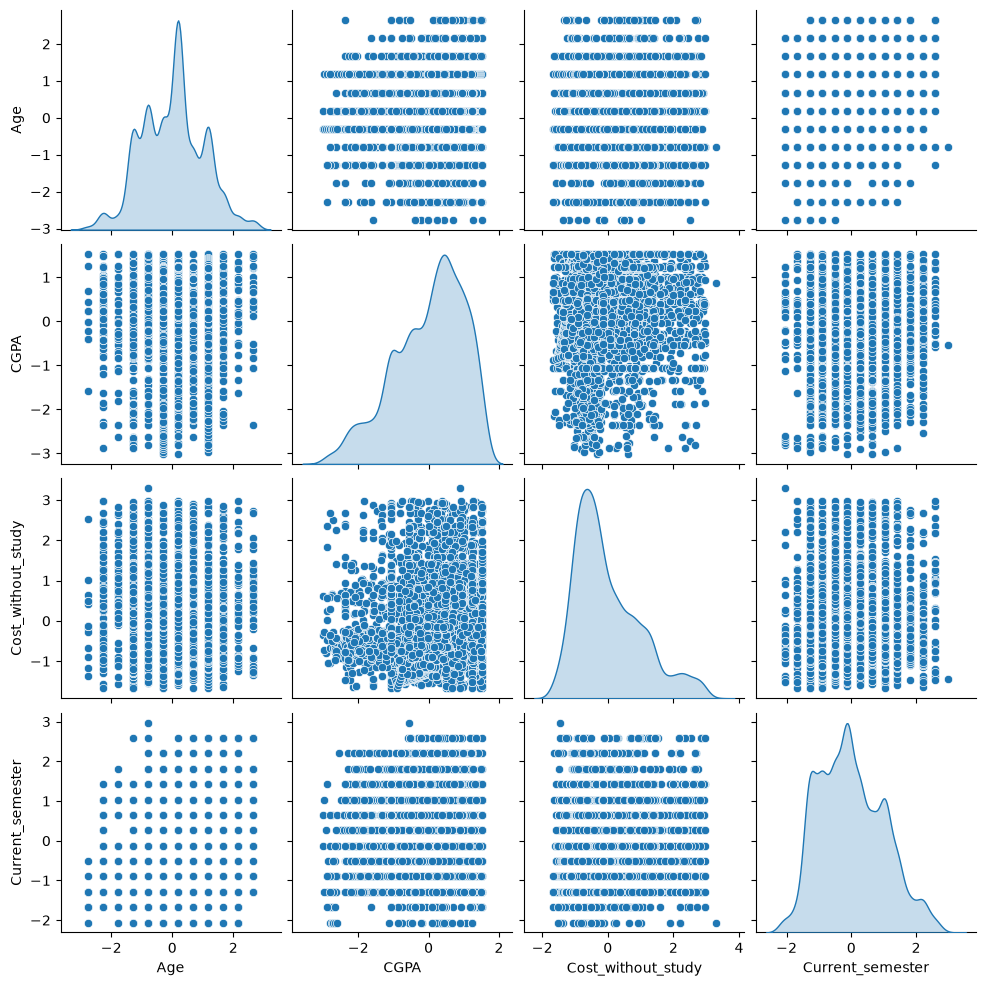

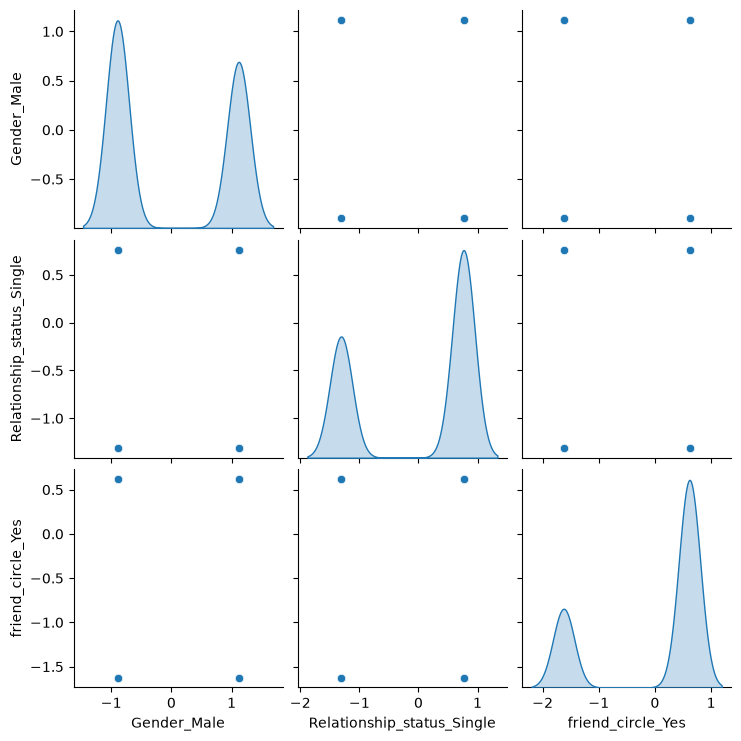

In [37]:

scaler = StandardScaler()
X_scaled = pd.DataFrame(
    scaler.fit_transform(X), 
    columns=X.columns, 
    index=X.index
)

num_cols = ['Age', 'CGPA', 'Cost_without_study', 'Current_semester']
sns.pairplot(X_scaled[num_cols], diag_kind='kde')
plt.show()

bin_cols = ['Gender_Male', 'Relationship_status_Single', 'friend_circle_Yes']
sns.pairplot(X_scaled[bin_cols], diag_kind='kde') 
plt.show()

### Анализ матрицы диаграмм рассеивания

На представленной матрице визуально видно, что между числовыми признаками (Age, CGPA, Cost_without_study, Current_semester) отсутствуют четкие линейные зависимости — облака точек не образуют наклонных линий или узких эллипсов. Распределения на диагонали (KDE) показывают, что Age и Cost_without_study имеют скошенную форму с выраженными хвостами, в то время как CGPA представляет собой многовершинное (ступенчатое) распределение.

Особое внимание привлекает структура точечных графиков: CGPA и Current_semester образуют строгую сетку (точки выстраиваются в вертикальные и горизонтальные ряды), что является прямым следствием дискретной природы этих признаков. 

В целом, диаграмма подтверждает, что данные представляют собой единое облако с неоднородной плотностью, а не изолированные группы.

### Выбор методов кластеризации

Для кластеризации было выбрано 2 метода - **Иерархическая кластеризация и EM-алгоритм**.

**Иерархическая кластеризация выбрана**, поскольку диаграммы рассеивания показали наличие скошенных распределений и вытянутых, неоднородных облаков (особенно по признаку Cost_without_study), а также ступенчатых структур (CGPA). Ward минимизирует внутрикластерную дисперсию при слиянии, что позволяет корректно работать с такими вытянутыми и несбалансированными группами, не навязывая им жесткую сферическую форму. Кроме того, метод не требует задавать число кластеров заранее.
 
**EM-алгоритм (GMM)** был выбран, поскольку визуальный анализ подтвердил, что данные представляют собой единое плотное облако без резких границ, а признаки имеют разную плотность и дискретную структуру. GMM способен моделировать кластеры в виде эллипсов с разной плотностью (за счет полной ковариационной матрицы), что лучше подходит для таких размытых структур. Дополнительным преимуществом является то, что GMM предоставляет вероятностную оценку принадлежности каждого студента, позволяя выявить случаи, которые на диаграммах рассеивания находятся в зонах пересечения облаков.

### Применение Иерархической кластеризации

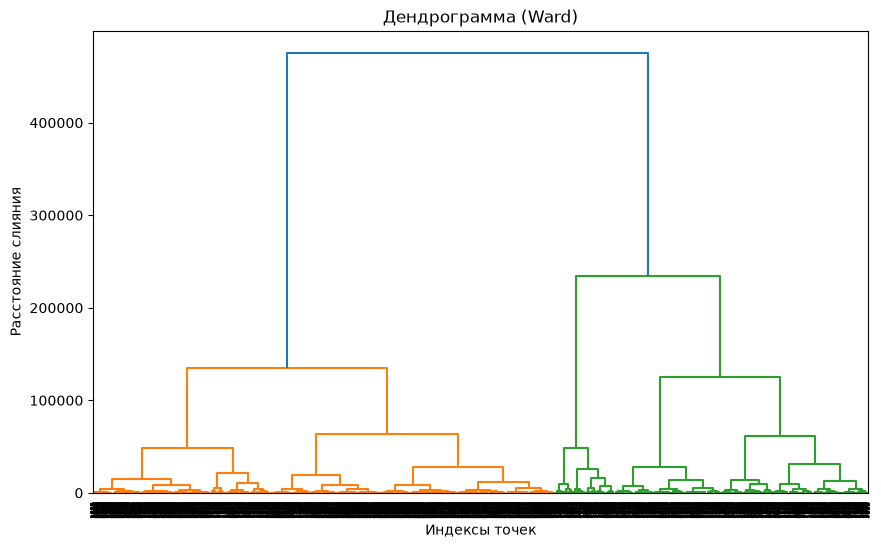

In [38]:
Z = linkage(X, method='ward')
plt.figure(figsize=(10, 6))
dendrogram(Z)
plt.title('Дендрограмма (Ward)')
plt.xlabel('Индексы точек')
plt.ylabel('Расстояние слияния')
plt.show()

#### Выбор количества кластеров

Выбор количества кластеров осуществлялся с помощью построения **дендрограммы**. 

На дендрограмме отчётливо видно, что данные разбиваются на **2 крупных кластера** на самом верхнем уровне.

Unique cluster IDs: [1 2]
Sizes: [ 549 3451]


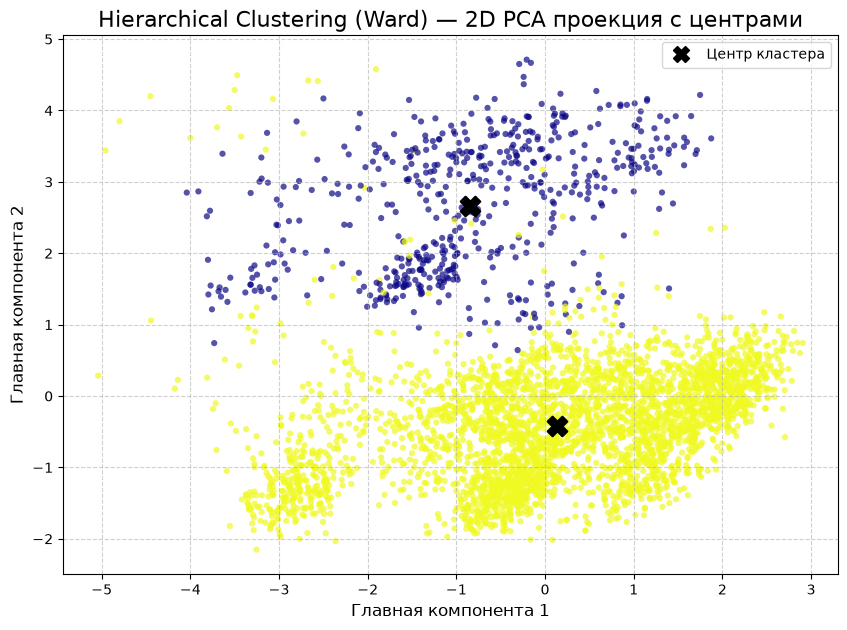

In [39]:
Z = linkage(X_scaled, method='ward')

labels_ward = fcluster(Z, t=2, criterion='maxclust')

unique, counts = np.unique(labels_ward, return_counts=True)
print('Unique cluster IDs:', unique)
print('Sizes:', counts)


pca_2d = PCA(n_components=2, random_state=42)
X_pca_2d = pca_2d.fit_transform(X_scaled)

plt.figure(figsize=(10, 7))


is_noise = labels_ward == -1
is_cluster = ~is_noise


if np.any(is_noise):
    plt.scatter(
        X_pca_2d[is_noise, 0], X_pca_2d[is_noise, 1], 
        c='lightgray', s=15, alpha=0.5, 
        label='Шум (-1)', edgecolors='none'
    )


scatter = plt.scatter(
    X_pca_2d[is_cluster, 0], X_pca_2d[is_cluster, 1], 
    c=labels_ward[is_cluster], cmap='plasma', s=20, alpha=0.7, edgecolors='none'
)


unique_clusters = [c for c in np.unique(labels_ward) if c != -1]

for cluster_id in unique_clusters:
    cluster_mask = labels_ward == cluster_id
    center_x = X_pca_2d[cluster_mask, 0].mean()
    center_y = X_pca_2d[cluster_mask, 1].mean()
    
    
    plt.scatter(
        center_x, center_y, 
        c='black', s=200, marker='X', edgecolors='black', linewidths=1.5,
        zorder=10 
    )
   


plt.title('Hierarchical Clustering (Ward) — 2D PCA проекция с центрами', fontsize=16)
plt.xlabel('Главная компонента 1', fontsize=12)
plt.ylabel('Главная компонента 2', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)


legend_elements = [
    Line2D([0], [0], marker='X', color='w', label='Центр кластера', markerfacecolor='black', markeredgecolor='black', markersize=12)
]
if np.any(is_noise):
    legend_elements.append(Line2D([0], [0], marker='o', color='w', label='Шум', markerfacecolor='lightgray', markersize=8))

plt.legend(handles=legend_elements, loc='best')
plt.show()


#### Построение диаграммы рассеивания в пространстве PCA
На диаграмме рассеивания визуально наблюдается **четкое разделение точек на две группы**.

 Центр 1 (верхняя группа) смещен в сторону положительных значений второй главной компоненты (PC2 ≈ 2.6), а Центр 2 (нижняя группа) — в сторону отрицательных значений (PC2 ≈ -0.5). Смещение центров вдоль оси PC1 при этом невелико, что указывает на то, что главная ось вариации данных (PC1) не является основным разделителем кластеров. Наибольший вклад в разбиение вносит вторая компонента.

#### Расчет внешних и внутренних метрик качества

In [40]:
def evaluate_clustering(X, labels, y_true, method_name="Метод"):
    print("="*60)
    print(f"ОЦЕНКА МЕТРИК: {method_name}")
    print("="*60)

    unique_labels = np.unique(labels)
    
    n_clusters = len([l for l in unique_labels if l != -1])
    
    if n_clusters == 0:
        print(" Все объекты признаны шумом (один кластер -1).")
        print("Внутренние метрики (Silhouette, CH, DB) НЕ РАССЧИТЫВАЮТСЯ.")
        return

    
    if n_clusters == 1:
        print("Алгоритм нашел только 1 кластер.")
        print("Внутренние метрики (Silhouette, CH, DB) НЕ РАССЧИТЫВАЮТСЯ (требуется минимум 2 кластера).")
        
        print(f"\nВнешние метрики (для справки):")
        print(f"ARI: {adjusted_rand_score(y_true, labels):.4f}")
        print(f"NMI: {normalized_mutual_info_score(y_true, labels):.4f}")
        return

    print("ВНУТРЕННИЕ МЕТРИКИ")
    print("-" * 40)
    
    sil = silhouette_score(X, labels)
    print(f"Silhouette Score:          {sil:.4f}")

    ch = calinski_harabasz_score(X, labels)
    print(f"Calinski-Harabasz Index:   {ch:.2f}")

    db = davies_bouldin_score(X, labels)
    print(f"Davies-Bouldin Index:      {db:.4f}")

    print("\n" + "="*60)
    print("ВНЕШНИЕ МЕТРИКИ")
    print("-" * 40)

    ari = adjusted_rand_score(y_true, labels)
    print(f"Adjusted Rand Index (ARI): {ari:.4f}")

    nmi = normalized_mutual_info_score(y_true, labels)
    print(f"NMI (Normalized MI):       {nmi:.4f}")

    v_measure = v_measure_score(y_true, labels)
    print(f"V-measure:                 {v_measure:.4f}")

    homogeneity = homogeneity_score(y_true, labels)
    completeness = completeness_score(y_true, labels)
    print(f"  ├─ Homogeneity:          {homogeneity:.4f} (насколько кластер чистый)")
    print(f"  └─ Completeness:         {completeness:.4f} (насколько класс собран)")
    print("\n")


evaluate_clustering(X_scaled, labels_ward, y, method_name="Hierarchical (Ward)")

ОЦЕНКА МЕТРИК: Hierarchical (Ward)
ВНУТРЕННИЕ МЕТРИКИ
----------------------------------------
Silhouette Score:          0.1855
Calinski-Harabasz Index:   433.86
Davies-Bouldin Index:      2.0211

ВНЕШНИЕ МЕТРИКИ
----------------------------------------
Adjusted Rand Index (ARI): -0.0407
NMI (Normalized MI):       0.0100
V-measure:                 0.0100
  ├─ Homogeneity:          0.0085 (насколько кластер чистый)
  └─ Completeness:         0.0122 (насколько класс собран)




Внутренние метрики (Silhouette = 0.19, Davies-Bouldin = 2.02) указывают на слабую, но всё же различимую геометрическую структуру кластеров. 

Значение **Silhouette**, близкое к 0.2, говорит о том, что границы между группами размыты и точки в некоторой степени пересекаются, однако алгоритм всё же смог найти определённый «разлом» в данных. 

Индекс **Davies-Bouldin**, превышающий 2.0, подтверждает, что внутрикластерный разброс сопоставим с расстоянием между центрами, что характерно для данных, не имеющих идеально плотных и изолированных сгустков.

Высокий индекс **Calinski-Harabasz** подтверждает, что межкластерный разброс существенно превышает внутрикластерный, то есть центры групп находятся на значительном удалении друг от друга.

Внешние метрики **(ARI ≈ 0, NMI = 0.01)** показывают, что данное разбиение практически не совпадает с реальным распределением студентов по депрессии. Алгоритм разделил данные на группы по другим признакам.

#### Анализ центров кластеров и интерпретация выделенных групп

In [41]:
df_original = df_encoded.copy()


df_original['Cluster'] = labels_ward


num_cols = df_original.select_dtypes(include=['number']).columns.drop('Cluster', errors='ignore').tolist()


raw_means = df_original.groupby('Cluster')[num_cols].mean()

print("СРЕДНИЕ ЗНАЧЕНИЯ ПРИЗНАКОВ ПО КЛАСТЕРАМ:")
display(raw_means.T.round(2))

СРЕДНИЕ ЗНАЧЕНИЯ ПРИЗНАКОВ ПО КЛАСТЕРАМ:


Cluster,1,2
Age,22.61,22.61
Current_semester,5.67,5.27
CGPA,3.42,3.41
Cost_without_study,18438.33,9570.13
Gender_Male,0.25,0.47
Family_background_Middle class,0.00,0.69
Family_background_Rich class,1.00,0.01
Relationship_status_In a Relationship,0.53,0.29
Relationship_status_Single,0.43,0.66
Marital_status_Separated,0.00,0.02



Для того чтобы понять, почему внешние метрики показывают такой низкий результат и по каким признакам разбиты данные, были расчитаны **центры кластеров**.

Разбиение данных произошло не по психологическим или академическим показателям (возраст, CGPA, здоровье, наличие друзей и отношений имеют примерно одинаковые значения), а по социально-экономическому статусу. 

**Кластер 1** объединил студентов из обеспеченных семей (Family_background_Rich class = 1; Family_background_Middle class = 0) с высокими расходами (Cost_without_study	= 18438.33), 

**Кластер 2** представляет собой основную массу студентов из среднего класса (Family_background_Middle class = 0.69; Family_background_Rich class = 0.009) с типичными расходами (Cost_without_study	= 9570.13). 

Алгоритм выявил наиболее очевидный контраст в данных — **финансовое благополучие**.



#### Использование EM-алгоритмa

Оценка моделей GMM:
  n_components=2: BIC=63708.7, Silhouette=0.226
  n_components=3: BIC=6714.3, Silhouette=0.107
  n_components=4: BIC=-40496.3, Silhouette=0.105
  n_components=5: BIC=-75597.1, Silhouette=0.146
  n_components=6: BIC=-97252.1, Silhouette=0.160
  n_components=7: BIC=-121375.2, Silhouette=0.131
  n_components=8: BIC=-134232.4, Silhouette=0.143
  n_components=9: BIC=-132025.5, Silhouette=0.113

[Метод локтя] Оптимальное число компонент: 5


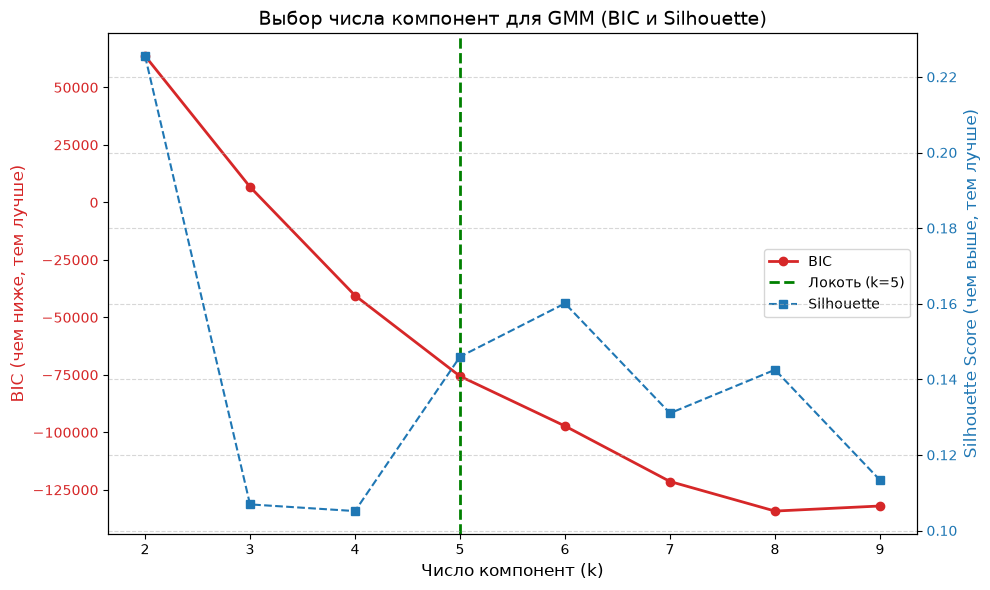

In [42]:


n_components_range = range(2, 10) 
bic_scores = []
silhouette_scores = []

print("Оценка моделей GMM:")
for n in n_components_range:
    gmm = GaussianMixture(
        n_components=n, 
        covariance_type='full',  
        random_state=42, 
        n_init=5                 
    )
    gmm.fit(X_scaled)
    
    labels = gmm.predict(X_scaled)
    
    bic = gmm.bic(X_scaled)
    bic_scores.append(bic)
    
    if len(np.unique(labels)) > 1:
        sil = silhouette_score(X_scaled, labels)
    else:
        sil = -1
    silhouette_scores.append(sil)
    
    print(f"  n_components={n}: BIC={bic:.1f}, Silhouette={sil:.3f}")


fig, ax1 = plt.subplots(figsize=(10, 6))

# Метод локтя
color1 = 'tab:red'
ax1.set_xlabel('Число компонент (k)', fontsize=12)
ax1.set_ylabel('BIC (чем ниже, тем лучше)', color=color1, fontsize=12)
ax1.plot(n_components_range, bic_scores, marker='o', color=color1, label='BIC', linewidth=2)
ax1.tick_params(axis='y', labelcolor=color1)


try:
    kl = KneeLocator(list(n_components_range), bic_scores, curve='convex', direction='decreasing')
    elbow_k = kl.elbow
    if elbow_k:
        ax1.axvline(x=elbow_k, color='green', linestyle='--', linewidth=2, label=f'Локоть (k={elbow_k})')
        print(f"\n[Метод локтя] Оптимальное число компонент: {elbow_k}")
except Exception as e:
    print("Для автоматического поиска локтя установите библиотеку: pip install kneed")

# График Silhouette 
ax2 = ax1.twinx()
color2 = 'tab:blue'
ax2.set_ylabel('Silhouette Score (чем выше, тем лучше)', color=color2, fontsize=12)
ax2.plot(n_components_range, silhouette_scores, marker='s', color=color2, linestyle='--', label='Silhouette')
ax2.tick_params(axis='y', labelcolor=color2)


lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='center right')

plt.title('Выбор числа компонент для GMM (BIC и Silhouette)', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.5)
fig.tight_layout()
plt.show()

Для того, чтобы определить оптимальное количество кластеров, были использованы **метод силуэта и метод локтя**.

Наилучшее значение метрики силуэта показала модель с **2 кластерами (0.226)**, и выбор был остановлен именно на этом варианте по трём причинам:

- Максимум метрики силуэта: Silhouette Score показывает, насколько объект похож на свой кластер по сравнению с соседними. Значение 0.226 при k=2 является максимальным среди всех проверенных вариантов (начиная с k=3, метрика падает до ~0.107–0.146). Это означает, что именно при двух кластерах точки наиболее плотно сгруппированы и наиболее далеко отстоят от соседней группы.

- Ограничение метода BIC (метод локтя): Хотя график BIC указывает на «локоть» при k=5, BIC продолжает снижаться вплоть до k=9, что свидетельствует о склонности алгоритма GMM к переобучению (выделению всё более мелких и неинтерпретируемых групп). При k=5 значение Silhouette (0.146) существенно ниже, чем при k=2, а сами кластеры становятся геометрически менее разделимыми.

- Интерпретируемость и согласованность: **Выбор k=2** согласуется с результатами иерархической кластеризации Ward, которая также выделила две устойчивые группы. Дальнейшее дробление не улучшает качество разбиения, а лишь «разрезает» уже существующие группы на части, что подтверждается падением метрики Silhouette.

Unique cluster IDs (GMM): [0 1]
Sizes (GMM): [3369  631]


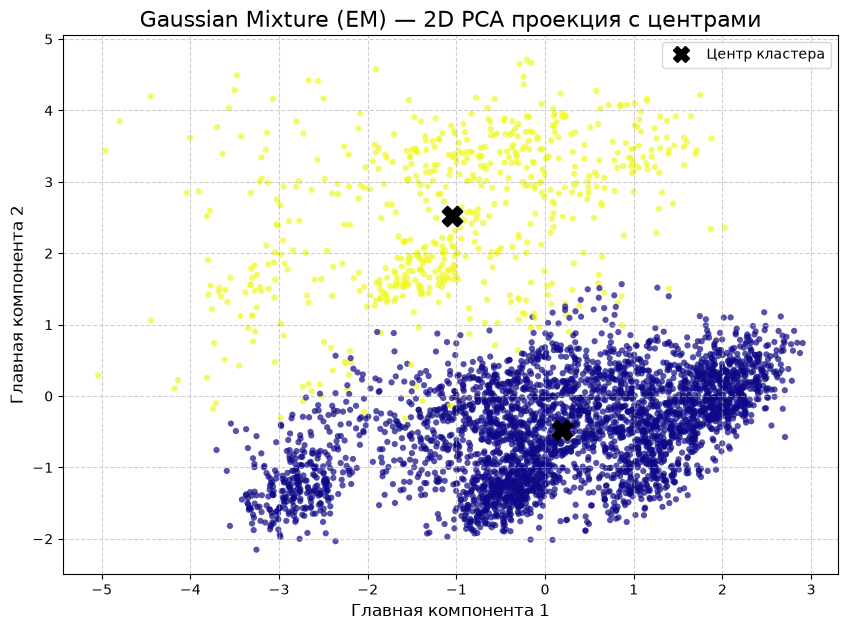

In [43]:

gmm = GaussianMixture(
    n_components=2, 
    covariance_type='full',
    random_state=42, 
    n_init=5                
)

gmm.fit(X_scaled)
probs = gmm.predict_proba(X_scaled)
labels_gmm = np.argmax(probs, axis=1)

unique, counts = np.unique(labels_gmm, return_counts=True)
print('Unique cluster IDs (GMM):', unique)
print('Sizes (GMM):', counts)


pca_2d = PCA(n_components=2, random_state=42)
X_pca_2d = pca_2d.fit_transform(X_scaled)

plt.figure(figsize=(10, 7))


is_noise = labels_gmm == -1
is_cluster = ~is_noise

if np.any(is_noise):
    plt.scatter(
        X_pca_2d[is_noise, 0], X_pca_2d[is_noise, 1], 
        c='lightgray', s=15, alpha=0.5, 
        label='Шум (-1)', edgecolors='none'
    )


scatter = plt.scatter(
    X_pca_2d[is_cluster, 0], X_pca_2d[is_cluster, 1], 
    c=labels_gmm[is_cluster], cmap='plasma', s=20, alpha=0.7, edgecolors='none'
)


unique_clusters = [c for c in np.unique(labels_gmm) if c != -1]

for cluster_id in unique_clusters:
    cluster_mask = labels_gmm == cluster_id
    center_x = X_pca_2d[cluster_mask, 0].mean()
    center_y = X_pca_2d[cluster_mask, 1].mean()
    
 
    plt.scatter(
        center_x, center_y, 
        c='black', s=200, marker='X', edgecolors='black', linewidths=1.5,
        zorder=10
    )
    


plt.title('Gaussian Mixture (EM) — 2D PCA проекция с центрами', fontsize=16)
plt.xlabel('Главная компонента 1', fontsize=12)
plt.ylabel('Главная компонента 2', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

legend_elements = [
    Line2D([0], [0], marker='X', color='w', label='Центр кластера', 
           markerfacecolor='black', markeredgecolor='black', markersize=12)
]
if np.any(is_noise):
    legend_elements.append(Line2D([0], [0], marker='o', color='w', label='Шум', 
                                  markerfacecolor='lightgray', markersize=8))

plt.legend(handles=legend_elements, loc='best')
plt.show()

#### Построение диаграммы рассеивания в пространстве PCA

Так же как и иерархическая кластеризация, алгоритм Gaussian Mixture (EM-алгоритм) разбил данные на **2 четких кластера**, которые визуально хорошо различимы на проекции главных компонент. 

EM-алгоритм нашел две плотные вероятностные области. 

#### Расчет внешних и внутренних метрик качества

In [44]:

evaluate_clustering(X_scaled, labels_gmm, y, method_name="EM (GMM)")

ОЦЕНКА МЕТРИК: EM (GMM)
ВНУТРЕННИЕ МЕТРИКИ
----------------------------------------
Silhouette Score:          0.2256
Calinski-Harabasz Index:   458.51
Davies-Bouldin Index:      2.2411

ВНЕШНИЕ МЕТРИКИ
----------------------------------------
Adjusted Rand Index (ARI): -0.0410
NMI (Normalized MI):       0.0103
V-measure:                 0.0103
  ├─ Homogeneity:          0.0091 (насколько кластер чистый)
  └─ Completeness:         0.0120 (насколько класс собран)




**Внутренние метрики** (Silhouette = 0.23, Davies-Bouldin = 2.24) указывают на слабое, но всё же различимое геометрическое разделение кластеров. 

Индекс **Calinski-Harabasz (458.51)** является достаточно высоким для данной размерности пространства, что говорит о превышении межкластерного разброса над внутрикластерным (центры групп находятся далеко друг от друга). 

Значение **Silhouette (0.23)** подтверждает, что границы между группами размыты и точки в некоторой степени пересекаются.

 Индекс **Davies-Bouldin (2.24)** показывает, что внутрикластерный разброс сопоставим с расстоянием между центрами.

 **Внешние метрики** (ARI = -0.04, NMI = 0.01) показывают полное отсутствие согласованности между найденными кластерами и исходными классами. Это означает, что алгоритм разделил студентов по другим признакам

#### Анализ центров кластеров и интерпретация выделенных групп

In [45]:
df_original = df_encoded.copy()


df_original['Cluster'] = labels_gmm


num_cols = df_original.select_dtypes(include=['number']).columns.drop('Cluster', errors='ignore').tolist()


raw_means = df_original.groupby('Cluster')[num_cols].mean()

print("СРЕДНИЕ ЗНАЧЕНИЯ ПРИЗНАКОВ ПО КЛАСТЕРАМ (В ИСХОДНЫХ ЕДИНИЦАХ):")
display(raw_means.T.round(2))

СРЕДНИЕ ЗНАЧЕНИЯ ПРИЗНАКОВ ПО КЛАСТЕРАМ (В ИСХОДНЫХ ЕДИНИЦАХ):


Cluster,0,1
Age,22.61,22.62
Current_semester,5.26,5.67
CGPA,3.41,3.42
Cost_without_study,9497.36,17674.44
Gender_Male,0.48,0.27
Family_background_Middle class,0.70,0.05
Family_background_Rich class,0.00,0.92
Relationship_status_In a Relationship,0.29,0.53
Relationship_status_Single,0.67,0.41
Marital_status_Separated,0.00,0.11



Для того чтобы понять, почему внешние метрики показывают такой низкий результат и по каким признакам разбиты данные, были расчитаны **центры кластеров**.

**Кластер 0** объединил студентов из семей среднего класса (средние расходы Cost_without_study — 9 497, доля Rich class равна 0)

**Кластер 1** представляет собой группу студентов из обеспеченных семей (средние расходы — 17 674, доля Rich class достигает 0.92).

 При этом центры кластеров практически не отличаются по возрасту (22.6 года), успеваемости (CGPA ~3.4) и состоянию здоровья.

**Алгоритм разделил студентов по уровню достатка, а не по наличию депрессии.**




### Сравнение результатов, полученных разными методами

In [46]:
methods = {
    'Hierarchical (Ward)': labels_ward,
    'EM (GMM)': labels_gmm,

}

metrics_list = []

for name, labels in methods.items():
    unique, counts = np.unique(labels, return_counts=True)
    row = {
        'Method': name,
        'Silhouette (↑)': silhouette_score(X_scaled, labels),
        'Calinski-Harabasz (↑)': calinski_harabasz_score(X_scaled, labels),
        'Davies-Bouldin (↓)': davies_bouldin_score(X_scaled, labels),
        'ARI (↑)': adjusted_rand_score(y, labels),
        'NMI (↑)': normalized_mutual_info_score(y, labels),
        'V-measure (↑)': v_measure_score(y, labels),
        'Sizes:': counts
        
        }
    metrics_list.append(row)


df_metrics = pd.DataFrame(metrics_list).set_index('Method')
df_metrics = df_metrics.round(4)

print("СРАВНИТЕЛЬНАЯ ТАБЛИЦА МЕТРИК КАЧЕСТВА КЛАСТЕРИЗАЦИИ")
print("="*60)
display(df_metrics)

СРАВНИТЕЛЬНАЯ ТАБЛИЦА МЕТРИК КАЧЕСТВА КЛАСТЕРИЗАЦИИ


,Silhouette (↑),Calinski-Harabasz (↑),Davies-Bouldin (↓),ARI (↑),NMI (↑),V-measure (↑),Sizes:
Method,,,,,,,
Hierarchical (Ward),0.1855,433.8573,2.0211,-0.0407,0.0100,0.0100,"[549, 3451]"
EM (GMM),0.2256,458.5096,2.2411,-0.0410,0.0103,0.0103,"[3369, 631]"


Оба алгоритма (иерархическая кластеризация Ward и EM-алгоритм) разделили данные на **два достаточно четких кластера**. 

**Анализ центров** показал, что оба метода выявили разбиение по уровню достатка: один кластер объединил студентов из обеспеченных семей с высокими расходами, а другой — представителей среднего класса.

**Внутренние метрики показывают, что EM-алгоритм (GMM) справился с геометрическим разделением чуть лучше**: у него выше Silhouette (0.2256 против 0.1855) и Calinski-Harabasz (458.5 против 433.9). Высокое значение Calinski-Harabasz означает, что в модели GMM отношение межкластерного разброса к внутрикластерному больше, то есть центры кластеров находятся дальше друг от друга относительно их размеров. Однако индекс Davies-Bouldin у GMM немного хуже (2.24 против 2.02 у Ward), что говорит о чуть большей «размазанности» кластеров.

Несмотря на геометрические успехи (подтвержденные всеми тремя внутренними метриками), исходно заданные классы (наличие депрессии) не совпадают с найденными кластерами. Об этом свидетельствуют крайне низкие значения **внешних метрик** (ARI ≈ 0, NMI ≈ 0.01) для обоих методов. 



### Исследование влияния параметров EM-алгоритма на качество кластеризации.

Главным параметром EM-алгоритма является количество кластеров. Переберем значения от 1 до 10 и вычислим метрики, чтобы исследовать влияние параметра на качество кластеризации.

Исследование влияния числа компонент (k) на GMM:

k =  2 | BIC =  63708.7 | AIC =  62003.1 | Sil = 0.226 | CH =  458.5 | DB = 2.241
k =  3 | BIC =   6714.3 | AIC =   4152.6 | Sil = 0.107 | CH =  391.2 | DB = 2.212
k =  4 | BIC = -40496.3 | AIC = -43914.0 | Sil = 0.105 | CH =  426.6 | DB = 2.313
k =  5 | BIC = -75597.1 | AIC = -79870.8 | Sil = 0.146 | CH =  450.5 | DB = 1.946
k =  6 | BIC = -97252.1 | AIC = -102381.7 | Sil = 0.160 | CH =  450.4 | DB = 1.776
k =  7 | BIC = -121375.2 | AIC = -127360.9 | Sil = 0.131 | CH =  436.5 | DB = 1.853
k =  8 | BIC = -134232.4 | AIC = -141074.0 | Sil = 0.143 | CH =  416.5 | DB = 1.945
k =  9 | BIC = -132025.5 | AIC = -139723.2 | Sil = 0.113 | CH =  374.9 | DB = 1.842
k = 10 | BIC = -137451.8 | AIC = -146005.4 | Sil = 0.159 | CH =  387.5 | DB = 1.981


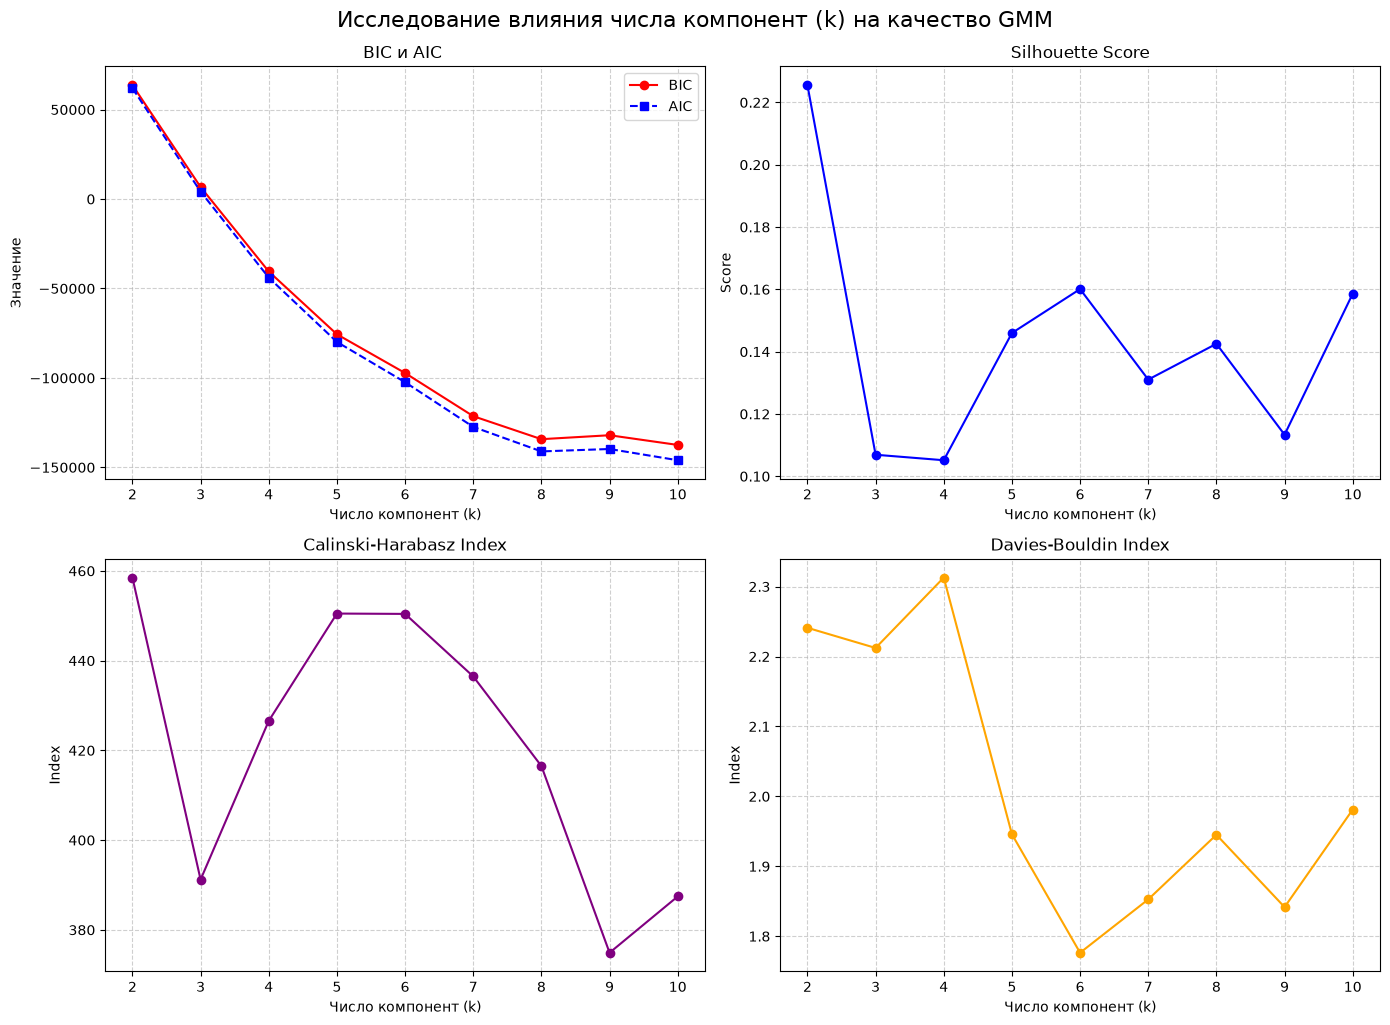

In [47]:

results = {
    'n_components': [],
    'BIC': [],
    'AIC': [],
    'Silhouette': [],
    'Calinski-Harabasz': [],
    'Davies-Bouldin': []
}

n_components_range = range(2, 11)

print("Исследование влияния числа компонент (k) на GMM:\n")

for n in n_components_range:
    gmm = GaussianMixture(
        n_components=n, 
        covariance_type='full',  
        random_state=42, 
        n_init=5                 
    )
    gmm.fit(X_scaled)
    
    labels = gmm.predict(X_scaled)
    
    bic = gmm.bic(X_scaled)
    aic = gmm.aic(X_scaled)
    sil = silhouette_score(X_scaled, labels)
    ch = calinski_harabasz_score(X_scaled, labels)
    db = davies_bouldin_score(X_scaled, labels)
    
  
    results['n_components'].append(n)
    results['BIC'].append(bic)
    results['AIC'].append(aic)
    results['Silhouette'].append(sil)
    results['Calinski-Harabasz'].append(ch)
    results['Davies-Bouldin'].append(db)
    
    print(f"k = {n:>2} | BIC = {bic:>8.1f} | AIC = {aic:>8.1f} | "
          f"Sil = {sil:.3f} | CH = {ch:>6.1f} | DB = {db:.3f}")


df_results = pd.DataFrame(results)


fig, axes = plt.subplots(2, 2, figsize=(14, 10))


axes[0, 0].plot(df_results['n_components'], df_results['BIC'], marker='o', label='BIC', color='red')
axes[0, 0].plot(df_results['n_components'], df_results['AIC'], marker='s', label='AIC', color='blue', linestyle='--')
axes[0, 0].set_title('BIC и AIC ', fontsize=12)
axes[0, 0].set_xlabel('Число компонент (k)')
axes[0, 0].set_ylabel('Значение')
axes[0, 0].legend()
axes[0, 0].grid(True, linestyle='--', alpha=0.6)

axes[0, 1].plot(df_results['n_components'], df_results['Silhouette'], marker='o', color='blue')
axes[0, 1].set_title('Silhouette Score', fontsize=12)
axes[0, 1].set_xlabel('Число компонент (k)')
axes[0, 1].set_ylabel('Score')
axes[0, 1].grid(True, linestyle='--', alpha=0.6)


axes[1, 0].plot(df_results['n_components'], df_results['Calinski-Harabasz'], marker='o', color='purple')
axes[1, 0].set_title('Calinski-Harabasz Index', fontsize=12)
axes[1, 0].set_xlabel('Число компонент (k)')
axes[1, 0].set_ylabel('Index')
axes[1, 0].grid(True, linestyle='--', alpha=0.6)


axes[1, 1].plot(df_results['n_components'], df_results['Davies-Bouldin'], marker='o', color='orange')
axes[1, 1].set_title('Davies-Bouldin Index', fontsize=12)
axes[1, 1].set_xlabel('Число компонент (k)')
axes[1, 1].set_ylabel('Index')
axes[1, 1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.suptitle('Исследование влияния числа компонент (k) на качество GMM', fontsize=16, y=1.02)
plt.show()

**Анализ BIC и AIC** показал, что эти информационные критерии продолжают снижаться вплоть до k=10, не образуя чёткого минимума («локтя»), что свидетельствует о склонности алгоритма к переобучению при увеличении числа компонент.

 В отличие от них, геометрические метрики указывают на оптимальное разбиение при k=2: именно здесь достигается максимальный Silhouette Score (0.226) и высокий Calinski-Harabasz (458.5). 
 
 Начиная с k=3, качество разделения резко падает (Silhouette снижается до 0.107), и хотя при k=6 наблюдается локальное улучшение (лучший Davies-Bouldin = 1.776), в целом структура становится более размытой.

Несмотря на то, что BIC/AIC «предлагают» максимально возможное число кластеров, с точки зрения геометрии и интерпретируемости данных оптимальным является k=2, подтверждая результаты иерархической кластеризации. Дальнейшее дробление не улучшает качество разбиения, а лишь подстраивается под шум в данных.

## Вывод

- Иерархическая кластеризация (Ward) была выбрана за способность работать с вытянутыми и несбалансированными структурами без априорного задания числа кластеров (выбор k по дендрограмме), а EM-алгоритм (GMM) — за возможность моделировать кластеры в виде эллипсов разной плотности.

- Оба алгоритма разделили данные на два устойчивых кластера, при этом анализ центров показал, что разбиение произошло по уровню достатка семьи, а не по наличию депрессии.

- Внутренние метрики продемонстрировали различимое геометрическое разделение (Silhouette ≈ 0.19–0.23, Davies-Bouldin ≈ 2.0–2.2) с небольшим преимуществом GMM по Silhouette и Calinski-Harabasz, тогда как внешние метрики оказались близки к нулю (ARI ≈ -0.04, NMI ≈ 0.01), подтвердив отсутствие связи найденных кластеров с целевой переменной Depression.

- Исследование числа компонент GMM показало, что BIC и AIC продолжают снижаться вплоть до k=10 (склонность к переобучению). Геометрические метрики (Silhouette, Calinski-Harabasz) достигают максимума именно при k=2, что подтверждает оптимальность двухкластерного разбиения.